# Let's get started!

This notebook will give you a feeling for what is possible with Python and its ecosystem.

## 16 March 2020

The Netherlands goes into lockdown. On the same day, **79 students** start getting a notification on their phones, **4 times a day, for 14 days**: *How worried are you? How lonely? How much time did you spend with people? With the news about the coronavirus?*

Let's see what happened to them, live, in about 20 lines of Python.

In [1]:
import pandas as pd
import seaborn as sns
import plotly.express as px

url = "https://raw.githubusercontent.com/wunderwald/Python_Workshop/main/data/0001_fried_ts.tsv"
df = pd.read_csv(url, sep="\t")
df

,id,scheduled,issued,response,duration,difficulties_relaxing,irritable,worry,nervous,nothing_look_forward,...,social_online,time_music,procrastinated,time_outdoors,covid_occupied,covid_worry,time_home,day,beep,date
0,1,2020-03-16 12:00:00,2020-03-16 12:00:00 CET,2020-03-16 12:04:45 CET,285.734,1.0,1.0,2.0,1.0,1.0,...,3.0,2.0,1.0,1.0,3.0,2.0,5.0,1,1,2020-03-16T11:04:45Z
1,1,2020-03-16 15:00:00,2020-03-16 15:00:00 CET,2020-03-16 15:30:22 CET,1822.742,2.0,1.0,2.0,1.0,1.0,...,3.0,2.0,2.0,2.0,2.0,2.0,5.0,1,2,2020-03-16T14:30:22Z
2,1,2020-03-16 18:00:00,2020-03-16 18:00:00 CET,2020-03-16 18:03:58 CET,238.774,1.0,1.0,3.0,1.0,1.0,...,4.0,3.0,3.0,1.0,3.0,1.0,5.0,1,3,2020-03-16T17:03:58Z
3,1,2020-03-16 21:00:00,2020-03-16 21:00:00 CET,2020-03-16 21:16:07 CET,967.132,1.0,1.0,3.0,2.0,1.0,...,3.0,1.0,3.0,1.0,3.0,2.0,5.0,1,4,2020-03-16T20:16:07Z
4,1,2020-03-17 12:00:00,2020-03-17 12:00:00 CET,2020-03-17 12:33:15 CET,1995.54,1.0,1.0,2.0,1.0,1.0,...,3.0,1.0,1.0,1.0,2.0,1.0,5.0,2,1,2020-03-17T11:33:15Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4367,79,2020-03-29 15:00:00,2020-03-29 15:00:00 EEST,2020-03-29 16:00:00 EEST,Expired,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14,2,2020-03-29T14:00:00Z
4368,79,2020-03-29 18:00:00,2020-03-29 18:00:00 EEST,2020-03-29 18:45:52 EEST,2752.428,1.0,1.0,1.0,1.0,1.0,...,1.0,3.0,2.0,2.0,1.0,1.0,5.0,14,3,2020-03-29T16:45:52Z
4369,79,2020-03-29 21:00:00,2020-03-29 21:00:00 EEST,2020-03-29 21:34:07 EEST,2047.129,2.0,2.0,2.0,1.0,2.0,...,3.0,2.0,2.0,1.0,1.0,2.0,5.0,14,4,2020-03-29T19:34:07Z
4370,79,2020-03-16 17:00:00,NaN,NaN,Expired,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2,NaN


### Every single answer, in one picture
One row per student, one column per prompt. White gaps = missed prompts.

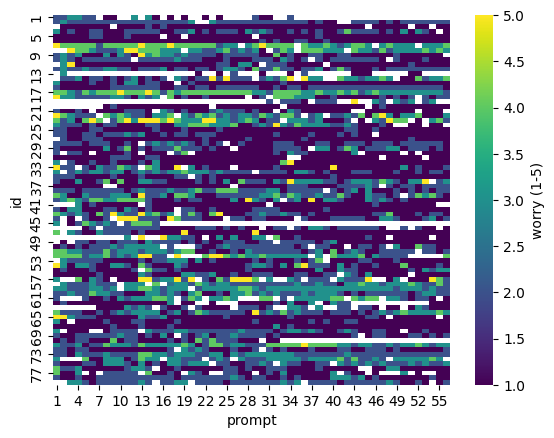

In [2]:
df["prompt"] = (df["day"] - 1) * 4 + df["beep"]
grid = df.pivot_table(index="id", columns="prompt", values="worry")
sns.heatmap(grid, cmap="viridis", cbar_kws={"label": "worry (1-5)"});

### How did students adapt over two weeks?

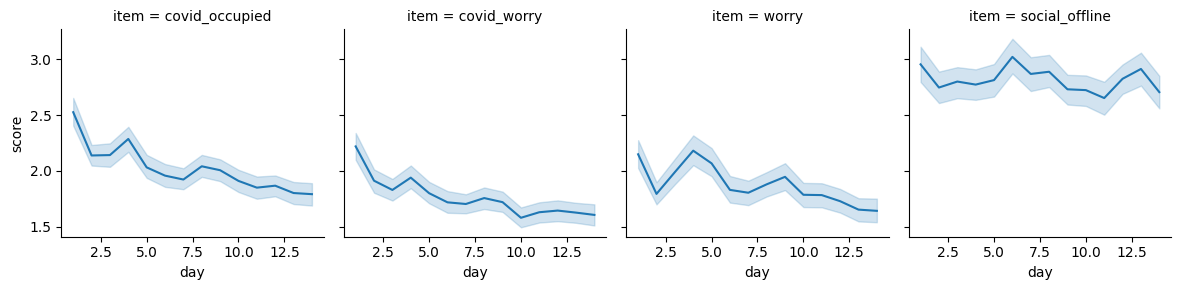

In [3]:
items = ["covid_occupied", "covid_worry", "worry", "social_offline"]
long = df.melt(id_vars=["id", "day"], value_vars=items, var_name="item", value_name="score")
sns.relplot(data=long, x="day", y="score", col="item", kind="line", height=3);

### Every dot is one student. Hover over them.

In [4]:
people = df.groupby("id")[["social_offline", "alone", "worry"]].mean().reset_index()
px.scatter(people, x="social_offline", y="alone", color="worry", hover_data=["id"],
           labels={"social_offline": "time with people (avg)", "alone": "loneliness (avg)"})

### And yes: multilevel models, too

In [5]:
import statsmodels.formula.api as smf

model = smf.mixedlm("covid_occupied ~ day", df.dropna(subset=["covid_occupied"]), groups="id").fit()
model.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
           Mixed Linear Model Regression Results
============================================================
Model:            MixedLM Dependent Variable: covid_occupied
No. Observations: 3933    Method:             REML          
No. Groups:       79      Scale:              0.5039        
Min. group size:  10      Log-Likelihood:     -4368.1920    
Max. group size:  56      Converged:          Yes           
Mean group size:  49.8                                      
-------------------------------------------------------------
             Coef.   Std.Err.     z     P>|z|  [0.025  0.975]
-------------------------------------------------------------
Intercept     2.332     0.063   36.986  0.000   2.208   2.455
day          -0.041     0.003  -14.299  0.000  -0.047  -0.035
id Var        0.267     0.063                                
============================================================

"""

---
In ~20 lines we have **downloaded** real research data, **visualised** all 4,000+ answers, **reshaped** it, made an **interactive** plot, and **fitted a multilevel model**.

**By tomorrow afternoon, you'll understand every single line.**

<small>Data: Fried, Papanikolaou & Epskamp (2022), *Clinical Psychological Science*, [doi:10.1177/21677026211017839](https://doi.org/10.1177/21677026211017839). CC-BY 4.0, distributed via [openESM](https://openesmdata.org).</small>

## Appendix: where does this data come from?

[openESM](https://openesmdata.org) collects 60+ open experience-sampling datasets. The `openesm` package downloads them directly (from Zenodo, which can be slow, so for the workshop we use a copy on GitHub).